In [1]:
# Run only if needed. Kaggle usually already contains many of these packages.
!pip install -q -U "transformers>=4.52.0"
!pip install "accelerate>=0.31.0" bitsandbytes datasets evaluate scikit-learn pandas numpy matplotlib tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 86.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 97.8 MB/s eta 0:00:00
  Attempting uninstall: cuda-bindings
    Found existing installation: cuda-bindings 13.2.0
    Uninstalling cuda-bindings-13.2.0:
      Successfully uninstalled cuda-bindings-13.2.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatibl

In [2]:
# Installs the HuggingFace datasets library
# !pip install datasets

In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Import plotly library
import plotly.graph_objects as go

In [5]:
dataset = load_dataset("ailsntua/QEvasion")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
train_df.head(2)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']
Test columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


,title,date,president,url,question_order,interview_question,interview_answer,gpt3.5_summary,gpt3.5_prediction,question,annotator_id,annotator1,annotator2,annotator3,inaudible,multiple_questions,affirmative_questions,index,clarity_label,evasion_label
0,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,How would you respond to the accusation that t...,85,None,None,None,False,False,False,0,Clear Reply,Explicit
1,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,Do you think President Xi is being sincere abo...,85,None,None,None,False,False,False,1,Ambivalent,General


In [6]:
# with open('test_df.txt', 'w') as file:
#     file.write("Id,Predicted\n")
#     for i, label in enumerate(test_df['clarity_label']):
#         file.write(str(i) + "," + str(label) + "\n")

In [7]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nLabel distribution (Train):")
print(train_df["clarity_label"].value_counts())

print("\nLabel distribution (Test):")
print(test_df["clarity_label"].value_counts())

Train shape: (3448, 20)
Test shape: (308, 20)

Label distribution (Train):
clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64

Label distribution (Test):
clarity_label
Ambivalent         206
Clear Reply         79
Clear Non-Reply     23
Name: count, dtype: int64


In [8]:
train_df[["question", "interview_answer"]].head(10)

,question,interview_answer
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou..."
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou..."
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p..."
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p..."
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l..."
5,Is there a danger of a cold war?,"Well, I hope I get to see Mr. Xi sooner than l..."
6,When will the President meet Mr. Xi?,"Well, I hope I get to see Mr. Xi sooner than l..."
7,How concerned are you about this lack of cons...,It wasn't so much an agreement that we would t...
8,Concerns about the lack of communication betw...,It's not a wedge issue of the Global South. It...
9,Inquiry about the reaction of Kyiv regarding ...,It's not a wedge issue of the Global South. It...


# **Data Cleaning**

In [9]:
def drop_conflicting_labels(df, name):
    # Find (question, answer) pairs with conflicting clarity labels across different annotators
    label_counts = df.groupby(["question", "interview_answer"])["clarity_label"].nunique()

    conflicting_pairs = label_counts[label_counts > 1].reset_index()
    conflicting_pairs.columns = ["question", "interview_answer", "unique_label_count"]

    print(f"Number of (question, answer) pairs with conflicting labels: {len(conflicting_pairs)}\n")

    # Drop (question, answer) pairs with conflicting clarity labels from the dataframe
    print(f"{name} size before dropping conflicting pairs: {len(df)}")

    df_clean = df.groupby(["question", "interview_answer"]).filter(
        lambda x: x["clarity_label"].nunique() == 1
    ).reset_index(drop=True)

    print(f"{name} size after dropping conflicting pairs: {len(df_clean)}\n")
    return df_clean

In [10]:
train_df = drop_conflicting_labels(train_df, "train_df")

Number of (question, answer) pairs with conflicting labels: 12

train_df size before dropping conflicting pairs: 3448
train_df size after dropping conflicting pairs: 3424



In [11]:
# test_df = drop_conflicting_labels(test_df, name="test_df")

In [12]:
def drop_inaudible(df, name):
    # Drop rows where inaudible = True
    print(f"Number of inaudible rows: {df['inaudible'].sum()}\n")

    print(f"{name} size before dropping inaudible rows: {len(df)}")

    df_clean = df[df["inaudible"] == False].reset_index(drop=True)

    print(f"{name} size after dropping inaudible rows: {len(df_clean)}\n")
    return df_clean

In [13]:
train_df = drop_inaudible(train_df, name="train_df")

Number of inaudible rows: 45

train_df size before dropping inaudible rows: 3424
train_df size after dropping inaudible rows: 3379



In [14]:
# test_df = drop_inaudible(test_df, name="test_df")Copy of without__Quantization technique_A2

In [15]:
# Display rows from the train_df where in interview_answer column has 5 or fewer words

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

train_df["answer_word_count"] = train_df["interview_answer"].apply(lambda x: len(x.split()))

train_df_sorted = train_df[train_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(train_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

pd.reset_option("display.max_rows")
pd.reset_option("display.max_colwidth")

,question,interview_answer,answer_word_count,clarity_label
0,"Discussion of defense budget increase, enemy base strike capability, and Japan-U.S. alliance.",No.,1,Clear Reply
1,Inquiring about the belief in an off-ramp for Vladimir Putin.,Yes.,1,Clear Reply
2,"The question asks if the President is willing to get involved militarily to defend Taiwan, if necessary.",Yes.,1,Clear Reply
3,Analysis of the response to China and the current status of cross-Straits relations,No.,1,Ambivalent
4,Are you satisfied with what came out in the communiqué?,Yes.,1,Clear Reply
5,Reasons for the shortened duration of the summit,Yes.,1,Ambivalent
6,Agreement with President Putin's statement regarding the absence of threats or scare tactics,Yes.,1,Clear Reply
7,Virtual summit participation,Yes.,1,Clear Reply
8,Transparency on the coronavirus origins,Yes.,1,Clear Reply
9,Agreement or disagreement with President Obama's view.,Yes.,1,Clear Reply


In [16]:
test_df["answer_word_count"] = test_df["interview_answer"].apply(lambda x: len(x.split()))

test_df_sorted = test_df[test_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(test_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

,question,interview_answer,answer_word_count,clarity_label
0,Do you think the decision by your G-20 counter...,Okay.,1,Ambivalent
1,What kind of punishment would you like to see ...,Okay.,1,Ambivalent
2,"Can we go back to North Korea, Mr. President?",Please.,1,Clear Reply
3,Clarification on the stance towards a nuclear ...,No.,1,Clear Reply
4,Previous conversations with Prime Minister Ma...,On Iran?,2,Clear Non-Reply
5,Permission to direct a question to President Hu.,Of course.,2,Clear Reply
6,Confidence in Republicans holding the House an...,"Yes, I am.",3,Clear Reply
7,Would you campaign for Mike Fitzpatrick?,I already have.,3,Clear Reply
8,"Is that a make-or-break issue for you, in term...",I already have.,3,Ambivalent
9,Reappointment of U.S. Attorney Patrick Fitzgerald,As a special prosecutor?,4,Clear Non-Reply


In [17]:
print(f"train_df size before dropping: {len(train_df)}")

# Drop rows with 0 words in the answer
train_df = train_df[train_df["answer_word_count"] > 0].reset_index(drop=True)

print(f"train_df size after dropping: {len(train_df)}")

train_df size before dropping: 3379
train_df size after dropping: 3379


In [18]:
# print(f"test_df size before dropping: {len(test_df)}")

# # Drop rows with 0 words in the answer
# test_df = test_df[test_df["answer_word_count"] > 0].reset_index(drop=True)

# print(f"test_df size after dropping: {len(test_df)}")

# **EDA part**

In [19]:
print(train_df["president"].unique())
print(f"\nTotal unique presidents: {train_df['president'].nunique()}")

['Joseph R. Biden' 'Donald J. Trump' 'Barack Obama' 'George W. Bush']

Total unique presidents: 4


In [20]:
print(train_df["clarity_label"].unique())

['Clear Reply' 'Ambivalent' 'Clear Non-Reply']


In [21]:
# Plot pie chart showing the overall distribution of clarity labels across all presidents
def plot_label_distribution_pie(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    colors = ["#2196F3", "#FF9800", "#F44336"]

    label_counts = df["clarity_label"].value_counts()
    values = [label_counts[label] for label in labels]

    fig = go.Figure(data=[go.Pie(labels=labels, values=values)])

    fig.update_traces(
        hoverinfo='label+percent',
        texttemplate='%{percent}<br>%{value}',
        textfont_size=20,
        marker=dict(colors=colors, line=dict(color='#000000', width=2))
    )

    fig.update_layout(
        title=dict(
          text="Overall Clarity Label Distribution",
          font=dict(size=24, family="Arial Black")
        ),
        legend_title="Clarity Label"
    )

    fig.show()

plot_label_distribution_pie(train_df)

In [22]:
plot_label_distribution_pie(test_df)

In [23]:
# Table and grouped bar chart showing answer length statistics (average, median, min, max) per clarity label
def print_length_statistics(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    rows = []

    for label in labels:
        subset = df[df["clarity_label"] == label]["interview_answer"]
        lengths = subset.apply(lambda x: len(x.split()))

        rows.append({
            "Label": label,
            "Average Length": round(lengths.mean(), 1),
            "Median": round(lengths.median(), 1),
            "Min": lengths.min(),
            "Max": lengths.max()
        })

    result_df = pd.DataFrame(rows).set_index("Label")
    display(result_df)

    print("\n\n")

    metrics = ["Max", "Average Length", "Median", "Min"]
    colors  = ["#F44336", "#FF9800", "#2196F3", "#FFEB3B"]

    fig = go.Figure(data=[
        go.Bar(
            name=metric,
            x=labels,
            y=[row[metric] for row in rows],
            text=[row[metric] for row in rows],
            textposition="outside",
            marker_color=color
        )
        for metric, color in zip(metrics, colors)
    ])

    fig.update_layout(
        barmode="group",
        title=dict(
            text="Answer Length Statistics per Clarity Label",
            font=dict(size=24, family="Arial Black")
        ),
        yaxis_title="Length (words)",
        legend_title="Metric",
    )

    fig.update_xaxes(
        tickangle=0,
        tickfont=dict(size=12, color="black"),
        title_text="Clarity Label",
        title_standoff=40
    )

    fig.show()

print_length_statistics(train_df)

,Average Length,Median,Min,Max
Label,,,,
Clear Reply,267.9,190.0,1,1592
Ambivalent,327.9,241.0,1,2117
Clear Non-Reply,136.0,40.0,1,1407


In [24]:
for threshold in [400, 500, 600, 700, 800, 900]:
    count = (test_df["interview_answer"].apply(lambda x: len(x.split())) > threshold).sum()
    print(f"Test answers > {threshold} words: {count} out of {len(test_df)} ({count/len(test_df)*100:.1f}%)")

Test answers > 400 words: 97 out of 308 (31.5%)
Test answers > 500 words: 70 out of 308 (22.7%)
Test answers > 600 words: 42 out of 308 (13.6%)
Test answers > 700 words: 29 out of 308 (9.4%)
Test answers > 800 words: 17 out of 308 (5.5%)
Test answers > 900 words: 13 out of 308 (4.2%)


In [25]:
import os, re, gc, json, time, random, warnings
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
)

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [26]:
LABELS = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]

NUMERIC_LABEL_MAP = {
    0: "Clear Reply",
    1: "Ambivalent",
    2: "Clear Non-Reply",
    "0": "Clear Reply",
    "1": "Ambivalent",
    "2": "Clear Non-Reply",
}

LABEL_ALIASES = {
    "clear reply": "Clear Reply",
    "clear_reply": "Clear Reply",
    "reply": "Clear Reply",
    "clear": "Clear Reply",

    "ambivalent": "Ambivalent",
    "ambiguous": "Ambivalent",
    "partial": "Ambivalent",
    "partially clear": "Ambivalent",

    "clear non-reply": "Clear Non-Reply",
    "clear non reply": "Clear Non-Reply",
    "clear_non_reply": "Clear Non-Reply",
    "non-reply": "Clear Non-Reply",
    "non reply": "Clear Non-Reply",
    "nonreply": "Clear Non-Reply",
}

def normalize_label(x):
    if pd.isna(x):
        return None

    if x in NUMERIC_LABEL_MAP:
        return NUMERIC_LABEL_MAP[x]

    s = str(x).strip()

    if s in NUMERIC_LABEL_MAP:
        return NUMERIC_LABEL_MAP[s]

    if s in LABELS:
        return s

    key = re.sub(r"\s+", " ", s.lower().replace("_", " ")).strip()

    if key in LABEL_ALIASES:
        return LABEL_ALIASES[key]

    if "non" in key and "reply" in key:
        return "Clear Non-Reply"

    if "ambiv" in key or "ambig" in key or "partial" in key:
        return "Ambivalent"

    if "clear" in key or "reply" in key:
        return "Clear Reply"

    return None


# ------------------------------------------------------------
# Create the normalized label column used by the rest of notebook
# ------------------------------------------------------------

train_df = train_df.copy()
train_df["label_norm"] = train_df["clarity_label"].apply(normalize_label)

print("\nLabel distribution:")
print(train_df["label_norm"].value_counts(dropna=False))

if train_df["label_norm"].isna().any():
    bad_labels = train_df.loc[train_df["label_norm"].isna(), "clarity_label"].unique()
    raise ValueError(f"Some labels could not be normalized: {bad_labels}")


Label distribution:
label_norm
Ambivalent         2001
Clear Reply        1029
Clear Non-Reply     349
Name: count, dtype: int64


In [27]:
train_part, valid_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["label_norm"],
)
train_part = train_part.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
print(train_part.shape, valid_df.shape)
print(valid_df["label_norm"].value_counts())

(2703, 22) (676, 22)
label_norm
Ambivalent         400
Clear Reply        206
Clear Non-Reply     70
Name: count, dtype: int64


In [28]:
MAX_ANSWER_WORDS = 750

def truncate_long_answer(answer, max_words=MAX_ANSWER_WORDS):
    words = answer.split()
    if len(words) > max_words:
        return " ".join(words[:max_words]) + " [TRUNCATED]"
    return answer

valid_df["interview_answer"] = valid_df["interview_answer"].apply(truncate_long_answer)
test_df["interview_answer"] = test_df["interview_answer"].apply(truncate_long_answer)

print("Truncated answers in valid_df:", valid_df["interview_answer"].str.contains(r"\[TRUNCATED\]").sum())
print("Truncated answers in test_df:", test_df["interview_answer"].str.contains(r"\[TRUNCATED\]").sum())

Truncated answers in valid_df: 54
Truncated answers in test_df: 18


In [29]:
def evaluate_predictions(y_true, y_pred, model_name, labels=LABELS):
    acc = accuracy_score(y_true, y_pred)
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    return {
        "model": model_name,
        "accuracy": acc,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f_macro,
        "precision_weighted": p_weighted,
        "recall_weighted": r_weighted,
        "f1_weighted": f_weighted,
    }

def compute_metrics(predictions, gold_labels, model_name, strategy_name):
    accuracy = accuracy_score(gold_labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        gold_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    macro_f1 = precision_recall_fscore_support(
        gold_labels,
        predictions,
        average="macro",
        zero_division=0
    )[2]

    print(f"\n{'='*60}")
    print(f"Model: {model_name}")
    print(f"Strategy: {strategy_name}")
    print(f"{'='*60}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1: {f1:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"\nClassification Report:")
    print(classification_report(gold_labels, predictions, zero_division=0))

    return {
        "model": model_name,
        "strategy": strategy_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_f1": macro_f1
    }

def print_full_report(y_true, y_pred, title):
    print("=" * 80)
    print(title)
    print("=" * 80)
    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(len(LABELS)))
    ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=35, ha="right")
    ax.set_yticklabels(LABELS)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

all_results = []

In [30]:
MODEL_NAME = "Qwen/Qwen3.5-0.8B"

# Set to None for final experiments.
D3_VALID_LIMIT = 100
D3_TEST_LIMIT = None

MAX_NEW_TOKENS_AGENT = 400
MAX_NEW_TOKENS_DECISION = 180

def load_qwen_model(model_name=MODEL_NAME):
    tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=dtype,
        device_map="auto" if torch.cuda.is_available() else None,
        trust_remote_code=True,
    )
    model.eval()
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer, model

qwen_tokenizer, qwen_model = load_qwen_model(MODEL_NAME)
print("Loaded", MODEL_NAME)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/12.8M [00:00<?, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/1.75G [00:00<?, ?B/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loaded Qwen/Qwen3.5-0.8B


In [31]:
def extract_json_object(text):
    if text is None:
        return {"raw": ""}
    text = text.strip()
    text = re.sub(r"^```(?:json)?", "", text, flags=re.IGNORECASE).strip()
    text = re.sub(r"```$", "", text).strip()
    try:
        obj = json.loads(text)
        if isinstance(obj, dict):
            return obj
    except Exception:
        pass
    match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if match:
        try:
            obj = json.loads(match.group(0))
            if isinstance(obj, dict):
                return obj
        except Exception:
            pass
    return {"raw": text}

def normalize_prediction_label(text):
    if text is None:
        return "Ambivalent"
    s = str(text).strip()
    normalized = normalize_label(s)
    if normalized in LABELS:
        return normalized
    key = re.sub(r"\s+", " ", s.lower().replace("_", " ")).strip()
    if "non" in key and "reply" in key:
        return "Clear Non-Reply"
    if "ambivalent" in key or "ambiguous" in key or "partial" in key or "unclear" in key:
        return "Ambivalent"
    if "clear reply" in key:
        return "Clear Reply"
    for label in LABELS:
        if label.lower() in key:
            return label
    return "Ambivalent"

def messages_to_prompt(messages):
    if hasattr(qwen_tokenizer, "apply_chat_template"):
        return qwen_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    rendered = ""
    for m in messages:
        rendered += f"{m['role'].upper()}:\n{m['content']}\n\n"
    return rendered + "ASSISTANT:\n"

import signal

class GenerationTimeoutException(Exception):
    pass

def _timeout_handler(signum, frame):
    raise GenerationTimeoutException("Generation exceeded timeout")

@torch.inference_mode()
def generate_chat(messages, max_new_tokens=160, timeout_seconds=600):
    prompt = messages_to_prompt(messages)
    inputs = qwen_tokenizer(prompt, return_tensors="pt", truncation=True, max_length=4096)
    inputs = {k: v.to(qwen_model.device) for k, v in inputs.items()}

    signal.signal(signal.SIGALRM, _timeout_handler)
    signal.alarm(timeout_seconds)
    try:
        output_ids = qwen_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None,
            pad_token_id=qwen_tokenizer.pad_token_id,
            eos_token_id=qwen_tokenizer.eos_token_id,
        )
        signal.alarm(0)
    except GenerationTimeoutException:
        signal.alarm(0)
        return ""

    new_tokens = output_ids[0][inputs["input_ids"].shape[-1]:]
    return qwen_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

In [32]:
QUESTION_INTENT_PROMPT = """
You are the Question Intent Agent for a response-clarity classification task.

Important dataset rule:
The TARGET_QUESTION may be only one sub-question extracted from a longer interview question.
Analyze ONLY the TARGET_QUESTION. Do not require the answer to address other questions unless they are necessary for this target question.

Your task:
Identify exactly what information would make an answer clear for the TARGET_QUESTION.

Think in terms of answer requirements:
- Is the question asking for yes/no?
- Is it asking what happened?
- Is it asking why/how something happened?
- Is it asking for a specific action, plan, reason, explanation, stance, or evaluation?
- Is it asking about a named person, event, country, policy, organization, or date?

Return exactly one JSON object and nothing else.

JSON schema:
{
  "question_type": "yes_no|what|why|how|when|where|who|stance|explanation|action_plan|evaluation|other",
  "question_intent": "one sentence describing what the target question asks",
  "must_address": [
    "specific requirement 1",
    "specific requirement 2"
  ],
  "clear_answer_criteria": "one sentence describing what a clear answer must contain",
  "minimal_sufficient_answer": "short description of the minimum information needed for Clear Reply"
}
""".strip()

In [33]:
def run_question_intent_agent(question):
    messages = [
        {"role": "system", "content": QUESTION_INTENT_PROMPT},
        {"role": "user", "content": f"Question:\n{question}"},
    ]

    raw = generate_chat(
        messages,
        max_new_tokens=MAX_NEW_TOKENS_AGENT
    )

    obj = extract_json_object(raw)
    obj["raw"] = raw
    return obj

In [34]:
ANSWER_CONTENT_PROMPT = """
You are the Answer Content Agent for a response-clarity classification task.

Important dataset rule:
The answer may respond to a longer interview question, but you must evaluate what it says with respect to the TARGET_QUESTION only.

Your task:
Extract what the answer actually says that is relevant to the TARGET_QUESTION.

Do not decide the final label.
Do not reward political rhetoric unless it answers the target question.
Do not infer facts that are not present in the answer.
An implicit answer is allowed only if the answer gives enough information to resolve the target question.

Look for:
- direct answer phrases: yes, no, I did, I did not, we will, we will not, because...
- concrete facts, actions, reasons, explanations, examples, commitments
- vague but related statements
- topic shifts
- refusals or declines to answer
- answers to a different sub-question

Return exactly one JSON object and nothing else.

JSON schema:
{
  "relevant_answer_summary": "one sentence summarizing only content relevant to the target question",
  "direct_answer_present": true,
  "direct_answer_text": "exact short phrase if present, otherwise empty string",
  "concrete_information": [
    "concrete relevant point 1",
    "concrete relevant point 2"
  ],
  "vague_or_general_information": [
    "vague/general relevant point 1"
  ],
  "off_target_content": [
    "content that answers a different question or changes topic"
  ],
  "refusal_or_non_answer_signals": [
    "signal 1"
  ]
}
""".strip()

GAP_EVASION_PROMPT = """
You are the Gap and Evasion Agent for response-clarity classification.

You receive:
1. the TARGET_QUESTION,
2. the answer,
3. the Question Intent Agent output,
4. the Answer Content Agent output.

Your task:
Compare what the target question requires with what the answer provides.

Important distinction:
- Missing small detail but mostly answering -> minor gap.
- Some relevant information but vague, incomplete, generic, or indirect -> partial gap.
- Mostly answering another topic, refusing, or avoiding the target question -> major gap.

Use these evasion categories when useful:
- explicit_answer: directly answers the target question.
- implicit_answer: not in requested form, but enough information is provided.
- partial_half_answer: answers only part of what was asked.
- general_answer: gives broad values/principles but lacks the requested specifics.
- dodging: avoids the precise target question while saying related things.
- deflection: redirects to another issue/person/topic.
- declining_to_answer: refuses, says cannot comment, or avoids due to confidentiality.
- claims_ignorance: says they do not know or cannot assess.
- clarification_only: asks for clarification or corrects framing without answering.
- irrelevant: no meaningful relation to the target question.

Do not assign the final top-level label.
Return exactly one JSON object and nothing else.

JSON schema:
{
  "coverage": "complete|mostly_complete|partial|minimal|none",
  "gap_level": "none|minor|partial|major",
  "best_evasion_category": "explicit_answer|implicit_answer|partial_half_answer|general_answer|dodging|deflection|declining_to_answer|claims_ignorance|clarification_only|irrelevant",
  "missing_requirements": [
    "missing requirement 1"
  ],
  "evidence_for_answering": [
    "short evidence from the answer"
  ],
  "evidence_for_evasion_or_gap": [
    "short evidence from the answer"
  ],
  "gap_explanation": "one concise sentence",
  "overall_verdict": "answers|partially_answers|does_not_answer"
}
""".strip()

DECISION_PROMPT = """
You are the Decision Agent for CLARITY response classification.

Assign exactly one final label for how clearly the ANSWER responds to the TARGET_QUESTION.

Valid labels:
1. Clear Reply
2. Ambivalent
3. Clear Non-Reply

Critical dataset rule:
Judge only the TARGET_QUESTION, not the whole interview question. If the answer addresses a different sub-question but not the target question, this is not a Clear Reply.

Definitions:

Clear Reply:
- The answer directly or implicitly provides the information requested by the target question.
- A yes/no question can be Clear Reply if the answer clearly implies yes or no.
- The answer does not need to be long.
- The answer may be politically framed, but it must still resolve the target question.

Ambivalent:
- The answer contains some relevant information but is incomplete, vague, overly general, or only partially responsive.
- The answer gives values, background, context, or related claims but does not fully satisfy the target question.
- The answer may answer part of a multi-part question but misses the current target question.
- Use Ambivalent for borderline cases where there is meaningful relevance but insufficient clarity.

Clear Non-Reply:
- The answer does not meaningfully answer the target question.
- It refuses to answer, says it cannot comment, claims ignorance, redirects to another topic, or only answers a different question.
- Use Clear Non-Reply when the response gives little or no usable information for the target question.

Decision rules:
- If coverage is complete or mostly_complete and the answer resolves the target question -> Clear Reply.
- If coverage is partial/minimal but there is relevant information -> Ambivalent.
- If coverage is none, or the response is mainly refusal/deflection/irrelevant -> Clear Non-Reply.
- Do not classify as Clear Non-Reply only because the answer is indirect. Indirect but sufficient answers are Clear Reply.
- Do not classify as Clear Reply only because the answer is fluent or politically detailed. It must answer the target question.
- Prefer Ambivalent over Clear Non-Reply when the answer has relevant but insufficient information.
- Prefer Ambivalent over Clear Reply when the answer is related but lacks the requested specific stance/action/reason.

Use overall_verdict from the Gap and Evasion Agent output as a direct signal for your label, but do not let it override the detailed coverage and gap_level fields:
- If overall_verdict is "answers", this supports Clear Reply, consistent with the coverage and gap_level fields.
- If overall_verdict is "partially_answers", this supports Ambivalent.
- If overall_verdict is "does_not_answer", this supports Clear Non-Reply.
- Use overall_verdict to double-check consistency with coverage and gap_level; if they disagree, prioritize the more detailed coverage and gap_level fields over the single-word overall_verdict.

Few-shot calibration examples:

Example A:
Target question: "Did you support the bill?"
Answer content: "Yes, I voted for it and I still support it."
Gap analysis: coverage complete; explicit answer.
Final label: Clear Reply.

Example B:
Target question: "What specific steps will you take to reduce prices?"
Answer content: "Families are struggling, this is important, and we are working every day."
Gap analysis: relevant but no specific steps.
Final label: Ambivalent.

Example C:
Target question: "Did you meet with the ambassador?"
Answer content: "I am not going to discuss private diplomatic conversations."
Gap analysis: declining to answer; no requested information.
Final label: Clear Non-Reply.

Example D:
Target question: "Why did unemployment increase?"
Answer content: "The economy has faced global pressure, energy shocks, and reduced demand."
Gap analysis: gives reasons even without saying 'because'.
Final label: Clear Reply.

Example E:
Target question: "Do you think President X is sincere?"
Answer content: "I am sincere about improving the relationship."
Gap analysis: answers the speaker's sincerity, not President X's sincerity.
Final label: Ambivalent.

Before assigning the final label, first summarize the key signals from the previous agents.

Return exactly one JSON object and nothing else.

JSON schema:
{
  "key_signals_used": {
    "coverage": "complete|mostly_complete|partial|minimal|none",
    "gap_level": "none|minor|partial|major",
    "overall_verdict": "answers|partially_answers|does_not_answer"
  },
  "label": "Clear Reply|Ambivalent|Clear Non-Reply",
  "confidence": 0.0,
  "main_reason": "one concise sentence",
  "used_rule": "short description of the rule that determined the label"
}
""".strip()

In [35]:
def run_answer_content_agent(question, answer):
    messages = [
        {"role": "system", "content": ANSWER_CONTENT_PROMPT},
        {
            "role": "user",
            "content": f"Question:\n{question}\n\nAnswer:\n{answer}",
        },
    ]

    raw = generate_chat(
        messages,
        max_new_tokens=MAX_NEW_TOKENS_AGENT
    )

    obj = extract_json_object(raw)
    obj["raw"] = raw
    return obj


def run_gap_evasion_agent(question, answer, question_intent, answer_content):
    user_payload = {
        "question": question,
        "answer": answer,
        "question_intent_agent_output": question_intent,
        "answer_content_agent_output": answer_content,
    }

    messages = [
        {"role": "system", "content": GAP_EVASION_PROMPT},
        {
            "role": "user",
            "content": json.dumps(user_payload, ensure_ascii=False, indent=2),
        },
    ]

    raw = generate_chat(
        messages,
        max_new_tokens=MAX_NEW_TOKENS_AGENT
    )

    obj = extract_json_object(raw)
    obj["raw"] = raw
    return obj


def run_decision_agent(question, answer, question_intent, answer_content, gap_evasion):
    user_payload = {
        "question": question,
        "answer": answer,
        "question_intent_agent_output": question_intent,
        "answer_content_agent_output": answer_content,
        "gap_and_evasion_agent_output": gap_evasion,
    }

    messages = [
        {"role": "system", "content": DECISION_PROMPT},
        {
            "role": "user",
            "content": json.dumps(user_payload, ensure_ascii=False, indent=2),
        },
    ]

    raw = generate_chat(
        messages,
        max_new_tokens=MAX_NEW_TOKENS_DECISION
    )

    obj = extract_json_object(raw)

    label = normalize_prediction_label(
        obj.get("label", raw)
    )

    return {
        "label": label,
        "confidence": obj.get("confidence", None),
        "rationale": obj.get("rationale", ""),
        "raw": raw,
    }

In [36]:
# exact column names
question_col = "question"
answer_col = "interview_answer"

# output paths
d3_valid_path = "d3_valid_results.csv"
d3_test_path = "d3_test_results.csv"

def run_d3_one(question, answer):
    question_intent = run_question_intent_agent(question)

    answer_content = run_answer_content_agent(
        question,
        answer
    )

    gap_evasion = run_gap_evasion_agent(
        question,
        answer,
        question_intent,
        answer_content
    )

    decision = run_decision_agent(
        question,
        answer,
        question_intent,
        answer_content,
        gap_evasion
    )

    return {
        "d3_question_intent": json.dumps(question_intent, ensure_ascii=False),
        "d3_answer_content": json.dumps(answer_content, ensure_ascii=False),
        "d3_gap_evasion": json.dumps(gap_evasion, ensure_ascii=False),
        "d3_decision": json.dumps(decision, ensure_ascii=False),
        "pred_d3": decision["label"],
        "d3_confidence": decision.get("confidence", None),
        "d3_rationale": decision.get("rationale", ""),
    }


def run_d3_dataframe(
    df,
    output_path,
    limit=None,
    checkpoint_every=25
):
    run_df = df.copy()

    if limit is not None:
        run_df = run_df.head(limit).copy()

    rows = []

    for i, row in tqdm(
        run_df.iterrows(),
        total=len(run_df),
        desc="D3-Agentic Prompting"
    ):
        try:
            out = run_d3_one(
                str(row[question_col]),
                str(row[answer_col])
            )

        except Exception as e:
            out = {
                "d3_question_intent": "",
                "d3_answer_content": "",
                "d3_gap_evasion": "",
                "d3_decision": json.dumps(
                    {"error": str(e)},
                    ensure_ascii=False
                ),
                "pred_d3": "Ambivalent",
                "d3_confidence": None,
                "d3_rationale": f"Fallback after error: {e}",
            }

        rows.append(out)

        if len(rows) % checkpoint_every == 0:
            checkpoint_df = pd.concat(
                [
                    run_df.iloc[:len(rows)].reset_index(drop=True),
                    pd.DataFrame(rows),
                ],
                axis=1,
            )

            checkpoint_df.to_csv(output_path, index=False)

            print(
                f"Checkpoint saved: {output_path} | rows={len(rows)}"
            )

    result_df = pd.concat(
        [
            run_df.reset_index(drop=True),
            pd.DataFrame(rows),
        ],
        axis=1,
    )

    result_df.to_csv(output_path, index=False)

    print("Saved:", output_path)

    return result_df

Running D3 validation
Validation rows available: 676
D3_VALID_LIMIT: 100


D3-Agentic Prompting:   0%|          | 0/100 [00:00<?, ?it/s]

Checkpoint saved: /content/d3_validation_outputs.csv | rows=25
Checkpoint saved: /content/d3_validation_outputs.csv | rows=50
Checkpoint saved: /content/d3_validation_outputs.csv | rows=75
Checkpoint saved: /content/d3_validation_outputs.csv | rows=100
Saved: /content/d3_validation_outputs.csv
D3-Agentic Prompting: Qwen/Qwen3.5-0.8B
                 precision    recall  f1-score   support

    Clear Reply       0.23      0.44      0.31        25
     Ambivalent       0.65      0.48      0.56        66
Clear Non-Reply       0.25      0.11      0.15         9

       accuracy                           0.44       100
      macro avg       0.38      0.35      0.34       100
   weighted avg       0.51      0.44      0.46       100



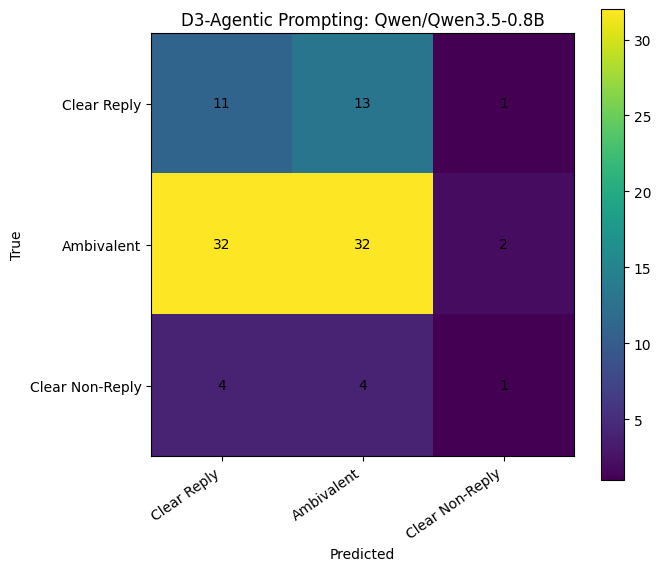

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,D3-Agentic Prompting: Qwen/Qwen3.5-0.8B,0.44,0.379035,0.34532,0.338641,0.512031,0.44,0.457539


Saved D3 validation outputs to: /content/d3_validation_outputs.csv

Model: Qwen3.5-0.8B
Strategy: D3-Agentic
Accuracy: 0.4400
Precision: 0.5120
Recall: 0.4400
F1: 0.4575
Macro F1: 0.3386

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.65      0.48      0.56        66
Clear Non-Reply       0.25      0.11      0.15         9
    Clear Reply       0.23      0.44      0.31        25

       accuracy                           0.44       100
      macro avg       0.38      0.35      0.34       100
   weighted avg       0.51      0.44      0.46       100



{'model': 'Qwen3.5-0.8B',
 'strategy': 'D3-Agentic',
 'accuracy': 0.44,
 'precision': 0.5120310464611376,
 'recall': 0.44,
 'f1': 0.4575393905611297,
 'macro_f1': 0.3386411495107147}

In [37]:
from pathlib import Path


try:
    WORK_DIR
except NameError:
    # For Kaggle submission change the below line to: WORK_DIR = Path("/kaggle/working")
    WORK_DIR = Path("/content")
    WORK_DIR.mkdir(parents=True, exist_ok=True)

# Optional: use Google Drive instead of temporary Colab storage.
# Uncomment these lines if you want outputs saved permanently.
#
# from google.colab import drive
# drive.mount("/content/drive")

try:
    D3_VALID_LIMIT
except NameError:
    D3_VALID_LIMIT = 100

# Basic safety checks
required_columns = [question_col, answer_col, "label_norm"]

missing_cols = [c for c in required_columns if c not in valid_df.columns]
if missing_cols:
    raise ValueError(
        f"valid_df is missing required columns: {missing_cols}. "
        "Make sure Cell 5 and Cell 6 were executed correctly."
    )

print("Running D3 validation")
print("Validation rows available:", len(valid_df))
print("D3_VALID_LIMIT:", D3_VALID_LIMIT)

d3_valid_path = WORK_DIR / "d3_validation_outputs.csv"

d3_valid_df = run_d3_dataframe(
    valid_df,
    output_path=d3_valid_path,
    limit=D3_VALID_LIMIT,
    checkpoint_every=25,
)

# Evaluate only the rows that D3 actually processed.
d3_y_true = d3_valid_df["label_norm"].tolist()
d3_y_pred = d3_valid_df["pred_d3"].tolist()

d3_result = evaluate_predictions(
    d3_y_true,
    d3_y_pred,
    f"D3-Agentic Prompting: {MODEL_NAME}",
)

# Avoid duplicate result rows if you rerun this cell.
all_results = [
    r for r in all_results
    if r["model"] != f"D3-Agentic Prompting: {MODEL_NAME}"
]
all_results.append(d3_result)

print_full_report(
    d3_y_true,
    d3_y_pred,
    f"D3-Agentic Prompting: {MODEL_NAME}"
)

plot_confusion_matrix(
    d3_y_true,
    d3_y_pred,
    f"D3-Agentic Prompting: {MODEL_NAME}"
)

results_df = (
    pd.DataFrame(all_results)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

display(results_df)

print("Saved D3 validation outputs to:", d3_valid_path)

# Print detailed metrics
compute_metrics(d3_y_pred, d3_y_true, "Qwen3.5-0.8B", "D3-Agentic")

In [38]:
d3_test_path = WORK_DIR / "d3_test_outputs.csv"

d3_test_df = run_d3_dataframe(
    test_df,
    output_path=d3_test_path,
    limit=D3_TEST_LIMIT,
    checkpoint_every=25,
)

# submission
with open("submission.csv", "w") as f:
    f.write("Id,Predicted\n")
    for i, pred in enumerate(d3_test_df["pred_d3"].tolist()):
        f.write(f"{i},{pred}\n")

print("Submission file saved!")
print(f"Total predictions: {len(d3_test_df)}")


# Print detailed metrics for test set
test_y_true = d3_test_df["clarity_label"].tolist()
test_y_pred = d3_test_df["pred_d3"].tolist()
compute_metrics(test_y_pred, test_y_true, "Qwen3.5-0.8B", "D3-Agentic Test Set")

D3-Agentic Prompting:   0%|          | 0/308 [00:00<?, ?it/s]

Checkpoint saved: /content/d3_test_outputs.csv | rows=25
Checkpoint saved: /content/d3_test_outputs.csv | rows=50
Checkpoint saved: /content/d3_test_outputs.csv | rows=75
Checkpoint saved: /content/d3_test_outputs.csv | rows=100
Checkpoint saved: /content/d3_test_outputs.csv | rows=125
Checkpoint saved: /content/d3_test_outputs.csv | rows=150
Checkpoint saved: /content/d3_test_outputs.csv | rows=175
Checkpoint saved: /content/d3_test_outputs.csv | rows=200
Checkpoint saved: /content/d3_test_outputs.csv | rows=225
Checkpoint saved: /content/d3_test_outputs.csv | rows=250
Checkpoint saved: /content/d3_test_outputs.csv | rows=275
Checkpoint saved: /content/d3_test_outputs.csv | rows=300
Saved: /content/d3_test_outputs.csv
Submission file saved!
Total predictions: 308

Model: Qwen3.5-0.8B
Strategy: D3-Agentic Test Set
Accuracy: 0.5779
Precision: 0.6382
Recall: 0.5779
F1: 0.5923
Macro F1: 0.4778

Classification Report:
                 precision    recall  f1-score   support

     Ambivalen

{'model': 'Qwen3.5-0.8B',
 'strategy': 'D3-Agentic Test Set',
 'accuracy': 0.577922077922078,
 'precision': 0.6382297907575165,
 'recall': 0.577922077922078,
 'f1': 0.5923270459354656,
 'macro_f1': 0.477774065411887}